<a href="https://colab.research.google.com/github/monikamoni022007-ux/ITA0520---COMPUTER-VISION/blob/main/EXPERIMENTS/Experiment_16_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving dog.jpeg to dog.jpeg
Image uploaded successfully: dog.jpeg


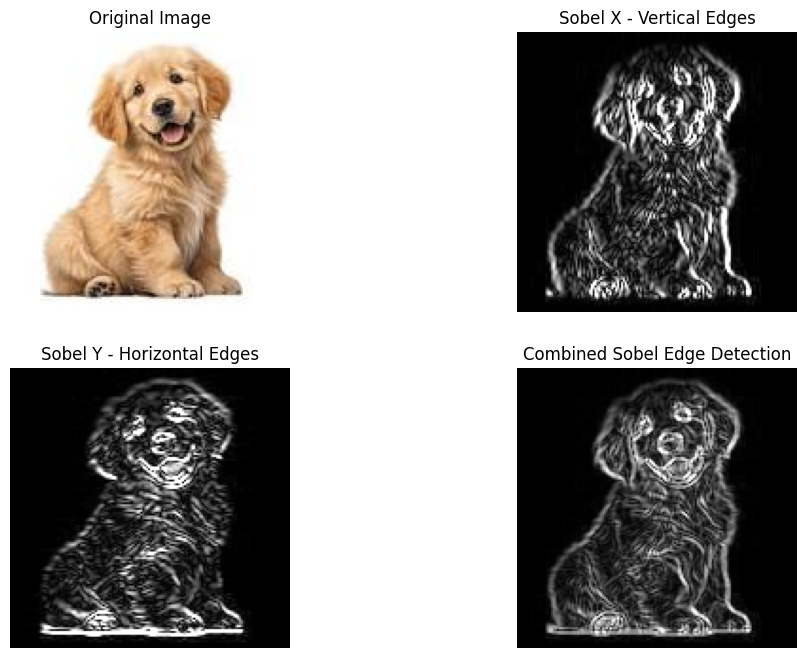

In [ ]:
from google.colab import files
uploaded = files.upload()

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Check if a file was actually uploaded
if not uploaded:
    print("No file uploaded. Please run the cell again and upload an image.")
else:
    filename = list(uploaded.keys())[0]
    image = cv2.imread(filename)

    # Check if OpenCV successfully read the image
    if image is None:
        print(f"Error: Could not read '{filename}'. Please make sure it is a valid image file (PNG, JPG, etc.).")
    else:
        print("Image uploaded successfully:", filename)

        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Compute Sobel gradients
        sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

        # Convert back to uint8 absolute values
        sobel_x = cv2.convertScaleAbs(sobel_x)
        sobel_y = cv2.convertScaleAbs(sobel_y)

        # Combine both X and Y gradients
        sobel_combined = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

        # Plotting the results
        plt.figure(figsize=(12, 8))

        plt.subplot(2, 2, 1)
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(2, 2, 2)
        plt.imshow(sobel_x, cmap="gray")
        plt.title("Sobel X - Vertical Edges")
        plt.axis("off")

        plt.subplot(2, 2, 3)
        plt.imshow(sobel_y, cmap="gray")
        plt.title("Sobel Y - Horizontal Edges")
        plt.axis("off")

        plt.subplot(2, 2, 4)
        plt.imshow(sobel_combined, cmap="gray")
        plt.title("Combined Sobel Edge Detection")
        plt.axis("off")

        plt.show()